# 01. 탐색적 데이터 분석 (EDA) – 경구약제 객체 검출

**목표**: 모델링 전에 데이터의 구조·품질·분포를 파악하고, 그 결과를 **전처리·검증·모델링 결정**으로 연결한다.

| 단계 | 질문 |
|---|---|
| 1. 구조 | 라벨은 어떤 형식이고, 이미지와 어떻게 연결되는가? |
| 2. 품질 | 누락·오류·불일치 라벨이 있는가? |
| 3. 클래스 | 클래스는 몇 개이고 얼마나 불균형한가? |
| 4. 박스 | 박스의 크기·위치·비율은 어떤가? |
| 5. 촬영 조건 | 각도·배경·조명·알약 속성은 얼마나 다양한가? |
| 6. 누수 위험 | 같은 조합의 사진이 여러 장인가? 검증을 어떻게 나눠야 하는가? |
| 7. Train vs Test | 테스트 이미지가 학습 이미지와 같은 분포인가? |
| 8. 결론 | 위 결과가 모델링에 주는 시사점은? |

## 0. 환경 설정
- Kaggle에서는 `/kaggle/input` 아래에서 데이터 폴더를 자동으로 찾는다.
- 로컬에서는 환경 변수 `PILL_DATA_DIR` 또는 레포 상위 폴더를 쓴다.
- 그래프는 Kaggle에서는 `/kaggle/working/figures`, 로컬에서는 `reports/figures`에 저장한다.

In [1]:
import json
import os
import platform
import subprocess
import sys
from collections import Counter
from itertools import combinations
from pathlib import Path

import matplotlib.patches as patches
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from PIL import Image

pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 200)


def find_data_root() -> Path:
    """train_annotations 폴더를 가진 데이터 루트를 찾는다."""
    if os.environ.get("PILL_DATA_DIR"):
        return Path(os.environ["PILL_DATA_DIR"])
    kaggle_input = Path("/kaggle/input")
    if kaggle_input.exists():
        for depth in ("*", "*/*", "*/*/*"):
            hits = list(kaggle_input.glob(f"{depth}/train_annotations"))
            if hits:
                return hits[0].parent
    # 로컬: 레포 폴더 옆(형제 폴더)의 sprint_ai_project1_data 또는 상위 폴더
    for cand in (Path.cwd(), *Path.cwd().parents):
        for root in (cand, cand / "sprint_ai_project1_data"):
            if (root / "train_annotations").exists():
                return root
    raise FileNotFoundError("데이터 폴더를 찾지 못했다. PILL_DATA_DIR 환경 변수를 지정하자.")


DATA_ROOT = find_data_root()
TRAIN_IMG_DIR = DATA_ROOT / "train_images"
TEST_IMG_DIR = DATA_ROOT / "test_images"
ANN_DIR = DATA_ROOT / "train_annotations"

IS_KAGGLE = Path("/kaggle/working").exists()
OUT_DIR = Path("/kaggle/working") if IS_KAGGLE else Path.cwd().parent / "reports"
FIG_DIR = OUT_DIR / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)

print("DATA_ROOT:", DATA_ROOT)
print("FIG_DIR  :", FIG_DIR)

DATA_ROOT: C:\Users\user\Desktop\ai_15기\###프로젝트\sprint_ai_project1_data
FIG_DIR  : C:\Users\user\Desktop\ai_15기\###프로젝트\pill-detection\reports\figures


In [2]:
def setup_korean_font() -> bool:
    """한글 폰트를 설정한다. 실패하면 False (영문 약품명으로 대체)."""
    if platform.system() == "Windows":
        plt.rcParams["font.family"] = "Malgun Gothic"
        return True
    try:
        import koreanize_matplotlib  # noqa: F401
        return True
    except ImportError:
        pass
    try:
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", "koreanize-matplotlib"], check=True)
        import koreanize_matplotlib  # noqa: F401
        return True
    except Exception as e:  # 인터넷이 꺼져 있으면 설치 실패
        print("한글 폰트 설치 실패 → 영문 약품명 사용:", e)
        return False


KOREAN_OK = setup_korean_font()
plt.rcParams["axes.unicode_minus"] = False
plt.rcParams["figure.dpi"] = 100
NAME_COL = "dl_name" if KOREAN_OK else "dl_name_en"


def save_fig(fig, name: str):
    """보고서에 쓸 수 있게 그래프를 PNG로 저장한다."""
    fig.savefig(FIG_DIR / f"{name}.png", dpi=150, bbox_inches="tight")

## 1. 데이터 구조
라벨 폴더는 `조합_json / 약코드 / 이미지명.json` 구조다. **JSON 하나에 알약 하나**의 COCO 형식 라벨이 들어 있다.
즉 이미지 한 장의 라벨이 여러 폴더에 흩어져 있으므로 **이미지 이름 기준으로 합쳐야** 한다.

In [3]:
json_paths = sorted(ANN_DIR.rglob("*.json"))
train_files = sorted(p.name for p in TRAIN_IMG_DIR.glob("*.png"))
test_files = sorted(TEST_IMG_DIR.glob("*.png"), key=lambda p: int(p.stem) if p.stem.isdigit() else p.stem)

print(f"라벨 JSON 파일   : {len(json_paths):,}")
print(f"조합 폴더        : {len(list(ANN_DIR.iterdir())):,}")
print(f"학습 이미지      : {len(train_files):,}")
print(f"테스트 이미지    : {len(test_files):,}")

with open(json_paths[0], encoding="utf-8") as f:
    sample = json.load(f)
print("\n[샘플 JSON 최상위 키]", list(sample.keys()))
print("[annotation 예시]", sample["annotations"][0])
print("[images 메타 키 수]", len(sample["images"][0]))

라벨 JSON 파일   : 763
조합 폴더        : 114
학습 이미지      : 232
테스트 이미지    : 842

[샘플 JSON 최상위 키] ['images', 'type', 'annotations', 'categories']
[annotation 예시] {'area': 35910, 'iscrowd': 0, 'bbox': [644, 845, 189, 190], 'category_id': 1900, 'ignore': 0, 'segmentation': [], 'id': 133, 'image_id': 34}
[images 메타 키 수] 50


In [4]:
META_KEYS = [
    "dl_name", "dl_name_en", "drug_N", "drug_dir", "back_color", "light_color",
    "camera_la", "camera_lo", "size", "drug_shape", "color_class1", "color_class2",
    "print_front", "print_back", "leng_long", "leng_short", "thick", "form_code_name",
]

rows = []
for p in json_paths:
    with open(p, encoding="utf-8") as f:
        d = json.load(f)
    img = d["images"][0]
    for a in d["annotations"]:
        x, y, w, h = a["bbox"]
        rows.append({
            "file_name": img["file_name"],
            "category_id": a["category_id"],
            "cat_name": d["categories"][0]["name"],
            "x": x, "y": y, "w": w, "h": h,
            "img_w": img["width"], "img_h": img["height"],
            "n_ann_in_json": len(d["annotations"]),
            "json_path": str(p.relative_to(ANN_DIR)),
            **{k: img.get(k) for k in META_KEYS},
        })

ann = pd.DataFrame(rows)
ann["combo"] = ann["file_name"].str.split("_").str[0]
print("annotation 수:", len(ann))
ann.head(3)

annotation 수: 763


,file_name,category_id,cat_name,x,y,w,h,img_w,img_h,n_ann_in_json,json_path,dl_name,dl_name_en,drug_N,drug_dir,back_color,light_color,camera_la,camera_lo,size,drug_shape,color_class1,color_class2,print_front,print_back,leng_long,leng_short,thick,form_code_name,combo
0,K-001900-016548-019607-029451_0_2_0_2_70_000_2...,1900,보령부스파정 5mg,644,845,189,190,976,1280,1,K-001900-016548-019607-029451_json\K-001900\K-...,보령부스파정 5mg,Buspar Tab. 5mg Boryung,K-001900,앞면,연회색 배경,주백색,70,0,200,장방형,하양,,BSP,5,8.0,4.5,2.5,나정,K-001900-016548-019607-029451
1,K-001900-016548-019607-029451_0_2_0_2_75_000_2...,1900,보령부스파정 5mg,148,241,181,181,976,1280,1,K-001900-016548-019607-029451_json\K-001900\K-...,보령부스파정 5mg,Buspar Tab. 5mg Boryung,K-001900,앞면,연회색 배경,주백색,75,0,200,장방형,하양,,BSP,5,8.0,4.5,2.5,나정,K-001900-016548-019607-029451
2,K-001900-016548-019607-029451_0_2_0_2_90_000_2...,1900,보령부스파정 5mg,167,248,184,182,976,1280,1,K-001900-016548-019607-029451_json\K-001900\K-...,보령부스파정 5mg,Buspar Tab. 5mg Boryung,K-001900,앞면,연회색 배경,주백색,90,0,200,장방형,하양,,BSP,5,8.0,4.5,2.5,나정,K-001900-016548-019607-029451


## 2. 라벨 품질 점검
모델은 라벨을 정답으로 믿고 배운다. 틀린 라벨은 그대로 오답을 학습시킨다. 그래서 아래 항목을 하나씩 확인한다.

1. 이미지와 라벨의 1:1 대응
2. JSON 하나에 annotation이 정확히 하나인지
3. `category_id`와 메타데이터 약 코드(`drug_N`)의 일치
4. 파일명에 적힌 알약 수 대비 **라벨 누락**
5. 이미지 범위를 벗어나거나 크기가 0인 **잘못된 박스**
6. JSON에 적힌 크기와 실제 이미지 크기의 일치

In [5]:
labeled = set(ann["file_name"])
print("1) 라벨 없는 이미지 :", len(set(train_files) - labeled))
print("   이미지 없는 라벨 :", len(labeled - set(train_files)))
print("2) annotation 개수가 1이 아닌 JSON :", int((ann["n_ann_in_json"] != 1).sum()))

ann["code_from_meta"] = ann["drug_N"].str.replace("K-", "", regex=False).astype(int)
print("3) category_id ≠ drug_N :", int((ann["category_id"] != ann["code_from_meta"]).sum()))
print("   클래스명 ≠ dl_name    :", int((ann["cat_name"] != ann["dl_name"]).sum()))

1) 라벨 없는 이미지 : 0
   이미지 없는 라벨 : 0
2) annotation 개수가 1이 아닌 JSON : 0
3) category_id ≠ drug_N : 0
   클래스명 ≠ dl_name    : 0


In [6]:
# 4) 파일명의 조합 코드 = 사진에 실제로 놓인 알약 목록
img_df = (
    ann.groupby("file_name")
    .agg(n_boxes=("category_id", "size"), labeled_codes=("category_id", lambda s: sorted(s)), camera_la=("camera_la", "first"))
    .reset_index()
)
img_df["combo"] = img_df["file_name"].str.split("_").str[0]
img_df["expected_codes"] = img_df["combo"].str.split("-").str[1:].apply(lambda xs: sorted(int(x) for x in xs))
img_df["n_expected"] = img_df["expected_codes"].str.len()
img_df["missing_codes"] = img_df.apply(lambda r: sorted(set(r.expected_codes) - set(r.labeled_codes)), axis=1)
img_df["extra_codes"] = img_df.apply(lambda r: sorted(set(r.labeled_codes) - set(r.expected_codes)), axis=1)

missing = img_df[img_df["missing_codes"].str.len() > 0]
print(f"4) 라벨 누락 이미지: {len(missing)}장 / 누락 박스 {missing['missing_codes'].str.len().sum()}개")
print("   파일명에 없는 클래스가 라벨된 이미지:", int((img_df["extra_codes"].str.len() > 0).sum()))
print(pd.crosstab(img_df["n_expected"], img_df["n_boxes"], rownames=["파일명상 알약 수"], colnames=["라벨 박스 수"]))
missing[["file_name", "n_expected", "n_boxes", "missing_codes"]]

4) 라벨 누락 이미지: 8장 / 누락 박스 8개
   파일명에 없는 클래스가 라벨된 이미지: 0
라벨 박스 수    2    3   4
파일명상 알약 수            
3          7  150   0
4          0    1  74


,file_name,n_expected,n_boxes,missing_codes
45,K-003351-013900-021325_0_2_0_2_70_000_200.png,3,2,[3351]
54,K-003351-013900-036637_0_2_0_2_70_000_200.png,3,2,[3351]
126,K-003351-020014-022074_0_2_0_2_90_000_200.png,3,2,[20014]
143,K-003351-021325-032310_0_2_0_2_90_000_200.png,3,2,[32310]
168,K-003351-032310-038162_0_2_0_2_70_000_200.png,3,2,[3351]
174,K-003351-033880-038162_0_2_0_2_75_000_200.png,3,2,[33880]
175,K-003351-035206-041768_0_2_0_2_70_000_200.png,3,2,[3351]
228,K-003544-004543-012247-016548_0_2_0_2_90_000_2...,4,3,[4543]


In [7]:
# 5) 잘못된 박스
ann["x2"] = ann["x"] + ann["w"]
ann["y2"] = ann["y"] + ann["h"]
bad_mask = (ann["x"] < 0) | (ann["y"] < 0) | (ann["x2"] > ann["img_w"]) | (ann["y2"] > ann["img_h"]) | (ann["w"] <= 0) | (ann["h"] <= 0)
bad = ann[bad_mask]
print(f"5) 잘못된 박스: {len(bad)}개")
display_cols = ["file_name", "category_id", "x", "y", "w", "h", "img_w", "img_h", "json_path"]
bad[display_cols]

5) 잘못된 박스: 1개


,file_name,category_id,x,y,w,h,img_w,img_h,json_path
239,K-003351-016262-018357_0_2_0_2_75_000_200.png,18357,6567,625,311,315,976,1280,K-003351-016262-018357_json\K-018357\K-003351-...


In [8]:
# 6) JSON 크기 vs 실제 이미지 크기 (헤더만 읽어서 빠름)
real_sizes = {f: Image.open(TRAIN_IMG_DIR / f).size for f in train_files}
size_mismatch = ann[[real_sizes[f] != (w, h) for f, w, h in zip(ann["file_name"], ann["img_w"], ann["img_h"])]]
print("6) JSON 크기 ≠ 실제 크기:", len(size_mismatch))
print("   학습 이미지 크기:", Counter(real_sizes.values()))
test_sizes = Counter(Image.open(p).size for p in test_files)
print("   테스트 이미지 크기:", test_sizes)

6) JSON 크기 ≠ 실제 크기: 0
   학습 이미지 크기: Counter({(976, 1280): 232})


   테스트 이미지 크기: Counter({(976, 1280): 842})


### 문제 이미지 눈으로 확인
숫자만 보고 판단하지 않고, 실제 이미지에 박스를 그려서 확인한다.
- **빨간 점선**: 이미지 범위를 벗어난 박스 (잘라서 표시)
- 제목의 `누락`: 파일명상 있어야 하지만 라벨이 없는 약 코드

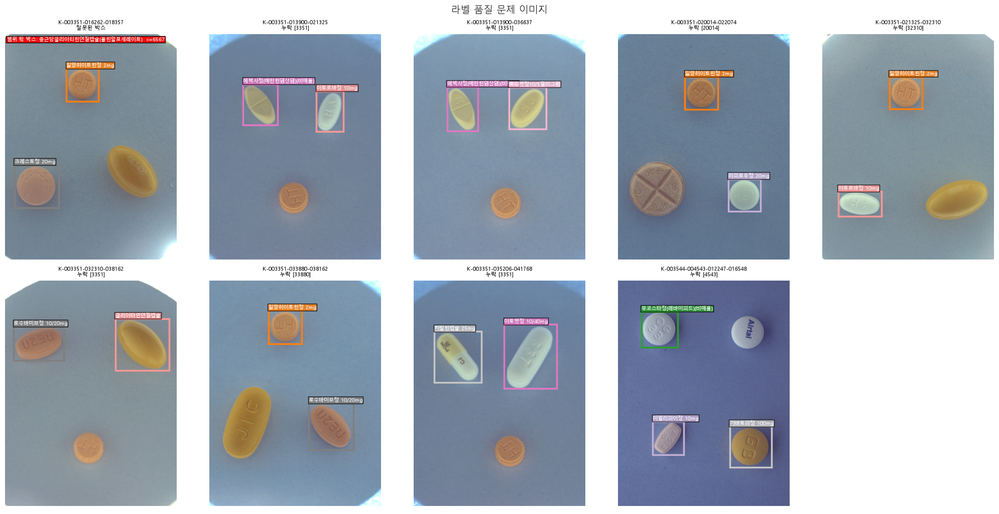

In [9]:
cat_ids = sorted(ann["category_id"].unique())
cmap = plt.get_cmap("tab20")
COLOR = {c: cmap(i % 20) for i, c in enumerate(cat_ids)}


def draw_boxes(ax, file_name, img_dir=TRAIN_IMG_DIR, title=None):
    img = Image.open(img_dir / file_name)
    ax.imshow(img)
    for _, r in ann[ann["file_name"] == file_name].iterrows():
        invalid = r.x2 > r.img_w or r.y2 > r.img_h or r.x < 0 or r.y < 0
        x, y = max(r.x, 0), max(r.y, 0)
        w, h = min(r.x2, r.img_w) - x, min(r.y2, r.img_h) - y
        if w <= 0 or h <= 0:  # 박스가 이미지 밖에 있으면 그리지 않고 경고만 표시
            ax.text(10, 40, f"범위 밖 박스: {r[NAME_COL]} x={r.x}", fontsize=7, color="white",
                    bbox=dict(fc="red", alpha=0.9, pad=1))
            continue
        ax.add_patch(patches.Rectangle(
            (x, y), max(w, 1), max(h, 1), fill=False, lw=2.5,
            ec="red" if invalid else COLOR[r.category_id], ls="--" if invalid else "-",
        ))
        ax.text(x, max(y - 8, 0), f"{r[NAME_COL]}", fontsize=7, color="white",
                bbox=dict(fc="red" if invalid else COLOR[r.category_id], alpha=0.8, pad=1))
    ax.set_title(title or file_name[:40], fontsize=8)
    ax.axis("off")


problem_files = list(bad["file_name"].unique()) + list(missing["file_name"])
n = len(problem_files)
ncols = 5
fig, axes = plt.subplots(int(np.ceil(n / ncols)), ncols, figsize=(4 * ncols, 5.2 * int(np.ceil(n / ncols))))
for ax in axes.flat[n:]:
    ax.axis("off")
for ax, f in zip(axes.flat, problem_files):
    row = img_df.set_index("file_name").loc[f]
    tag = f"누락 {row.missing_codes}" if row.missing_codes else "잘못된 박스"
    draw_boxes(ax, f, title=f"{f.split('_')[0]}\n{tag}")
fig.suptitle("라벨 품질 문제 이미지", fontsize=14)
plt.tight_layout()
save_fig(fig, "01_label_problems")
plt.show()

**관찰**
- 라벨 누락 이미지 8장 모두 **빠진 알약이 사진에 실제로 있다** (주로 주황색 원형 `HT` 각인의 일양하이트린정).
  알약이 없는 게 아니라 박스만 빠졌다. 그대로 학습하면 이 알약이 **배경(오답)** 으로 학습된다.
- 잘못된 박스 이미지에는 박스 없는 노란 타원형 알약이 보인다. x=6567은 자릿수 **오타**로 보인다.
  후보 x=567, x=656을 실제로 그려서 어느 쪽이 맞는지 확인한다.

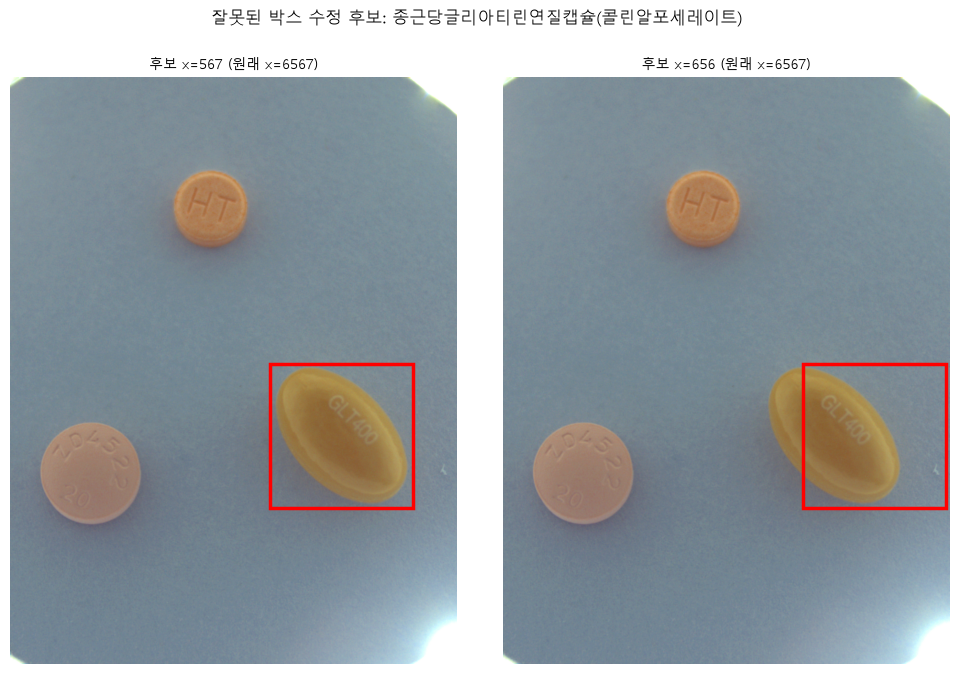

In [10]:
bad_r = bad.iloc[0]
cands = [567, 656]
fig, axes = plt.subplots(1, len(cands), figsize=(10, 6.5))
for ax, cx in zip(axes, cands):
    ax.imshow(Image.open(TRAIN_IMG_DIR / bad_r.file_name))
    ax.add_patch(patches.Rectangle((cx, bad_r.y), bad_r.w, bad_r.h, fill=False, lw=2.5, ec="red"))
    ax.set_title(f"후보 x={cx} (원래 x={bad_r.x})", fontsize=10)
    ax.axis("off")
fig.suptitle(f"잘못된 박스 수정 후보: {bad_r[NAME_COL]}", fontsize=12, y=1.03)
plt.tight_layout()
save_fig(fig, "01b_invalid_box_candidates")
plt.show()

**결론**: **x=567**이 알약(GLT400 각인)에 정확히 맞는다. `6567`은 앞자리 `6`이 잘못 들어간 입력 오류다.
전처리에서 x=567로 수정한다.

## 3. 클래스 분포

클래스 수: 56
박스 수 – 최대 153 / 중앙값 9 / 최소 3
불균형 비율 (최대/최소): 51배
박스 10개 미만 클래스: 29개 (52%)
단 1개 조합에만 등장하는 클래스: 17개
상위 5개 클래스가 차지하는 박스 비율: 37%


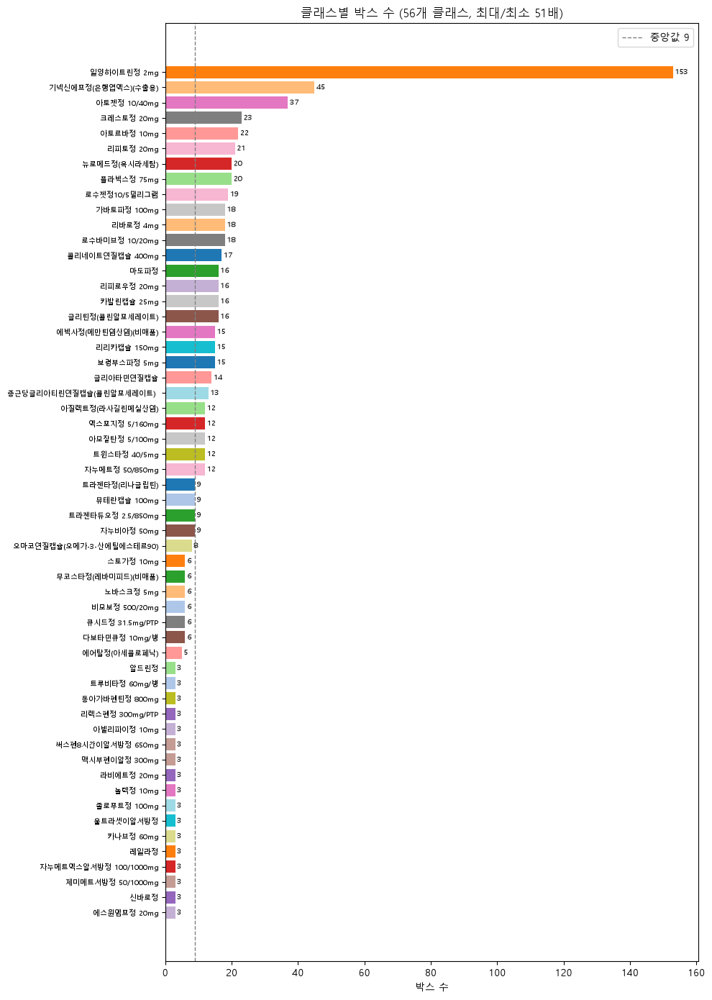

In [11]:
cls = (
    ann.groupby("category_id")
    .agg(name=(NAME_COL, "first"), n_boxes=("file_name", "size"), n_images=("file_name", "nunique"), n_combos=("combo", "nunique"))
    .sort_values("n_boxes", ascending=False)
    .reset_index()
)
print(f"클래스 수: {len(cls)}")
print(f"박스 수 – 최대 {cls.n_boxes.max()} / 중앙값 {cls.n_boxes.median():.0f} / 최소 {cls.n_boxes.min()}")
print(f"불균형 비율 (최대/최소): {cls.n_boxes.max() / cls.n_boxes.min():.0f}배")
print(f"박스 10개 미만 클래스: {(cls.n_boxes < 10).sum()}개 ({(cls.n_boxes < 10).mean():.0%})")
print(f"단 1개 조합에만 등장하는 클래스: {(cls.n_combos == 1).sum()}개")
print(f"상위 5개 클래스가 차지하는 박스 비율: {cls.n_boxes.head(5).sum() / cls.n_boxes.sum():.0%}")

fig, ax = plt.subplots(figsize=(10, 14))
bars = ax.barh(cls["name"][::-1], cls["n_boxes"][::-1], color=[COLOR[c] for c in cls["category_id"][::-1]])
ax.axvline(cls.n_boxes.median(), ls="--", c="gray", lw=1, label=f"중앙값 {cls.n_boxes.median():.0f}")
ax.bar_label(bars, fontsize=7, padding=2)
ax.set_xlabel("박스 수")
ax.set_title(f"클래스별 박스 수 (56개 클래스, 최대/최소 {cls.n_boxes.max() // cls.n_boxes.min()}배)")
ax.tick_params(axis="y", labelsize=7)
ax.legend()
plt.tight_layout()
save_fig(fig, "02_class_distribution")
plt.show()

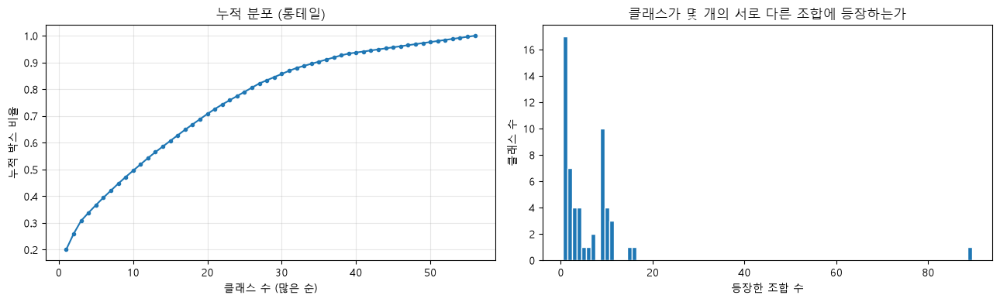

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
sorted_counts = cls["n_boxes"].values
axes[0].plot(np.arange(1, len(sorted_counts) + 1), np.cumsum(sorted_counts) / sorted_counts.sum(), marker="o", ms=3)
axes[0].set(xlabel="클래스 수 (많은 순)", ylabel="누적 박스 비율", title="누적 분포 (롱테일)")
axes[0].grid(alpha=0.3)
axes[1].hist(cls["n_combos"], bins=range(1, cls.n_combos.max() + 2), edgecolor="white", align="left")
axes[1].set(xlabel="등장한 조합 수", ylabel="클래스 수", title="클래스가 몇 개의 서로 다른 조합에 등장하는가")
plt.tight_layout()
save_fig(fig, "03_class_longtail")
plt.show()

## 4. 이미지당 알약 수

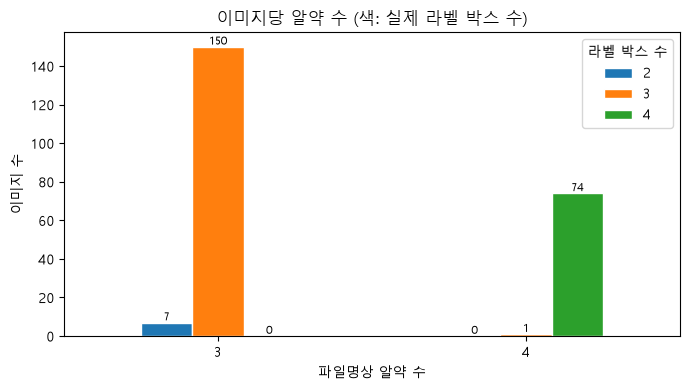

In [13]:
fig, ax = plt.subplots(figsize=(7, 4))
ct = pd.crosstab(img_df["n_expected"], img_df["n_boxes"])
ct.plot(kind="bar", ax=ax, rot=0, edgecolor="white")
ax.set(xlabel="파일명상 알약 수", ylabel="이미지 수", title="이미지당 알약 수 (색: 실제 라벨 박스 수)")
ax.legend(title="라벨 박스 수")
for c in ax.containers:
    ax.bar_label(c, fontsize=8)
plt.tight_layout()
save_fig(fig, "04_pills_per_image")
plt.show()

## 5. 바운딩 박스 분석
박스 크기와 위치는 **입력 해상도, 앵커와 증강 설계**의 근거가 된다. 잘못된 박스 1개는 분석에서 뺀다.

             w        h  area_ratio   aspect
count  762.000  762.000     762.000  762.000
mean   249.928  265.699       0.056    0.992
std     73.788   95.699       0.034    0.269
min    125.000  126.000       0.019    0.396
25%    189.250  191.000       0.029    0.828
50%    230.000  227.000       0.043    1.000
75%    285.000  316.500       0.075    1.041
max    529.000  664.000       0.218    2.108


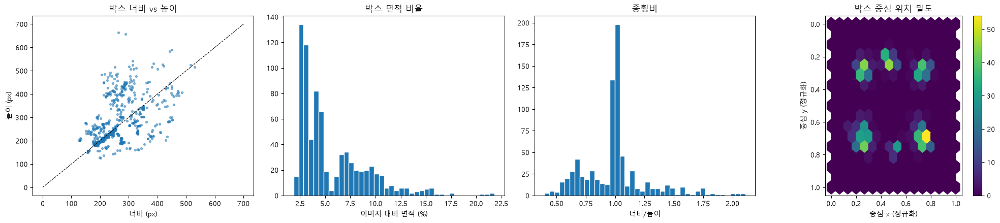

In [14]:
box = ann[~bad_mask].copy()
box["area_ratio"] = box["w"] * box["h"] / (box["img_w"] * box["img_h"])
box["aspect"] = box["w"] / box["h"]
box["cx"] = (box["x"] + box["w"] / 2) / box["img_w"]
box["cy"] = (box["y"] + box["h"] / 2) / box["img_h"]
print(box[["w", "h", "area_ratio", "aspect"]].describe().round(3))

fig, axes = plt.subplots(1, 4, figsize=(20, 4.5))
axes[0].scatter(box["w"], box["h"], s=8, alpha=0.5)
axes[0].plot([0, 700], [0, 700], "k--", lw=0.8)
axes[0].set(xlabel="너비 (px)", ylabel="높이 (px)", title="박스 너비 vs 높이")
axes[1].hist(box["area_ratio"] * 100, bins=40, edgecolor="white")
axes[1].set(xlabel="이미지 대비 면적 (%)", title="박스 면적 비율")
axes[2].hist(box["aspect"], bins=40, edgecolor="white")
axes[2].set(xlabel="너비/높이", title="종횡비")
hb = axes[3].hexbin(box["cx"], box["cy"], gridsize=15, cmap="viridis", extent=(0, 1, 0, 1))
axes[3].invert_yaxis()
axes[3].set_aspect(1280 / 976)
axes[3].set(xlabel="중심 x (정규화)", ylabel="중심 y (정규화)", title="박스 중심 위치 밀도")
fig.colorbar(hb, ax=axes[3])
plt.tight_layout()
save_fig(fig, "05_bbox_stats")
plt.show()

**관찰**: 박스 중심이 몇 개의 **고정된 자리(슬롯)** 에 몰려 있다. 알약을 정해진 위치에 놓고 촬영한 것으로 보인다.
모델이 "이 자리에는 알약이 있다"는 위치 편향을 배우지 않도록 **이동·모자이크 증강**이 필요하다.

In [15]:
# YOLO 입력 해상도별로 박스가 몇 픽셀이 되는지 (긴 변 1280 기준으로 축소)
for imgsz in (640, 800, 1024, 1280):
    scale = imgsz / 1280
    short = np.minimum(box["w"], box["h"]) * scale
    print(f"imgsz={imgsz:4d}: 박스 짧은 변 최소 {short.min():5.1f}px / 중앙값 {short.median():5.1f}px")

imgsz= 640: 박스 짧은 변 최소  62.5px / 중앙값 107.0px
imgsz= 800: 박스 짧은 변 최소  78.1px / 중앙값 133.8px
imgsz=1024: 박스 짧은 변 최소 100.0px / 중앙값 171.2px
imgsz=1280: 박스 짧은 변 최소 125.0px / 중앙값 214.0px


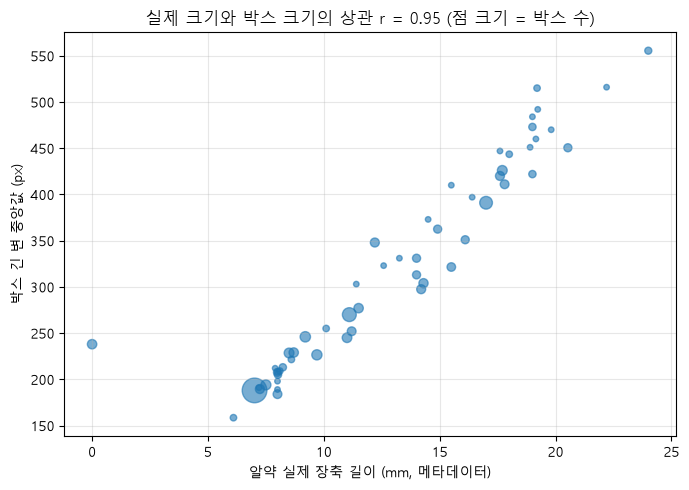

In [16]:
# 클래스별 박스 크기 vs 실제 알약 크기(mm) → 크기도 클래스를 구분하는 단서인가?
size_by_cls = box.groupby("category_id").agg(
    name=(NAME_COL, "first"), med_w=("w", "median"), med_h=("h", "median"),
    leng_long=("leng_long", "first"), n=("w", "size"),
)
size_by_cls["box_long"] = np.maximum(size_by_cls["med_w"], size_by_cls["med_h"])
corr = size_by_cls[["box_long", "leng_long"]].astype(float).corr().iloc[0, 1]

fig, ax = plt.subplots(figsize=(7, 5))
ax.scatter(size_by_cls["leng_long"].astype(float), size_by_cls["box_long"], s=size_by_cls["n"] * 2 + 10, alpha=0.6)
ax.set(xlabel="알약 실제 장축 길이 (mm, 메타데이터)", ylabel="박스 긴 변 중앙값 (px)",
       title=f"실제 크기와 박스 크기의 상관 r = {corr:.2f} (점 크기 = 박스 수)")
ax.grid(alpha=0.3)
plt.tight_layout()
save_fig(fig, "06_size_vs_physical")
plt.show()

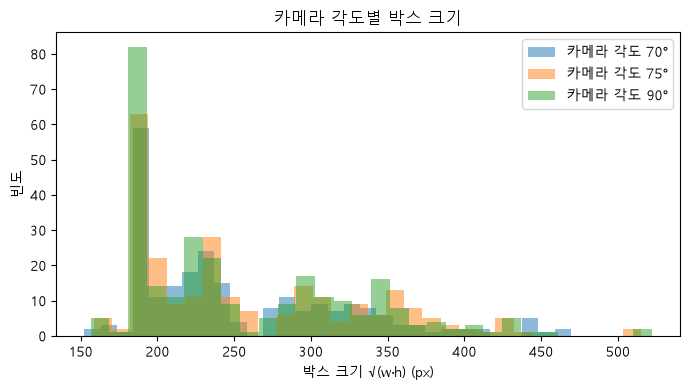

In [17]:
fig, ax = plt.subplots(figsize=(7, 4))
for la, g in box.groupby("camera_la"):
    ax.hist(np.sqrt(g["w"] * g["h"]), bins=30, alpha=0.5, label=f"카메라 각도 {la}°")
ax.set(xlabel="박스 크기 √(w·h) (px)", ylabel="빈도", title="카메라 각도별 박스 크기")
ax.legend()
plt.tight_layout()
save_fig(fig, "07_size_by_angle")
plt.show()

## 6. 촬영 조건과 알약 속성

back_color  : {'연회색 배경': 763}
light_color : {'주백색': 763}
camera_lo   : {0: 763}
size        : {200: 763}


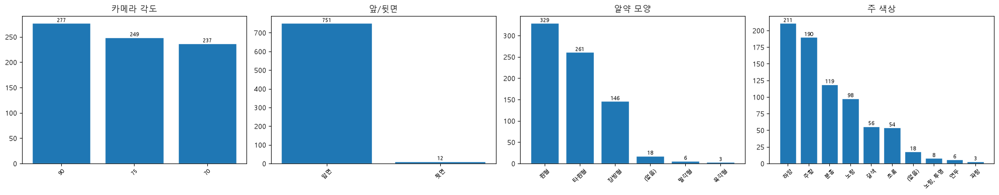

In [18]:
for col in ["back_color", "light_color", "camera_lo", "size"]:
    print(f"{col:12s}: {dict(Counter(ann[col]))}")

fig, axes = plt.subplots(1, 4, figsize=(20, 4))
for ax, col, title in zip(
    axes, ["camera_la", "drug_dir", "drug_shape", "color_class1"], ["카메라 각도", "앞/뒷면", "알약 모양", "주 색상"]
):
    vc = ann[col].fillna("(없음)").astype(str).value_counts()
    ax.bar(vc.index, vc.values, edgecolor="white")
    ax.set_title(title)
    ax.tick_params(axis="x", rotation=45, labelsize=8)
    for i, v in enumerate(vc.values):
        ax.text(i, v, str(v), ha="center", va="bottom", fontsize=8)
plt.tight_layout()
save_fig(fig, "08_capture_conditions")
plt.show()

In [19]:
# 생김새가 비슷해 헷갈릴 수 있는 클래스: 모양 + 색이 같은 그룹
look = ann.drop_duplicates("category_id").assign(look=lambda d: d["drug_shape"].fillna("?") + " / " + d["color_class1"].fillna("?"))
groups = look.groupby("look")[NAME_COL].apply(list)
groups = groups[groups.str.len() >= 2].sort_values(key=lambda s: s.str.len(), ascending=False)
print(f"모양·색이 같은 클래스 그룹 {len(groups)}개 (헷갈릴 수 있는 후보)")
for k, v in groups.items():
    print(f"  [{k}] {len(v)}종: {', '.join(map(str, v[:6]))}{' ...' if len(v) > 6 else ''}")

모양·색이 같은 클래스 그룹 12개 (헷갈릴 수 있는 후보)
  [원형 / 하양] 7종: 스토가정 10mg, 알드린정, 리피토정 20mg, 리피로우정 20mg, 아질렉트정(라사길린메실산염), 무코스타정(레바미피드)(비매품) ...
  [장방형 / 하양] 7종: 보령부스파정 5mg, 써스펜8시간이알서방정 650mg, 리렉스펜정 300mg/PTP, 맥시부펜이알정 300mg, 뉴로메드정(옥시라세탐), 리리카캡슐 150mg ...
  [타원형 / 갈색] 6종: 신바로정, 다보타민큐정 10mg/병, 트루비타정 60mg/병, 종근당글리아티린연질캡슐(콜린알포세레이트) , 콜리네이트연질캡슐 400mg, 글리아타민연질캡슐
  [타원형 / 노랑] 6종: 레일라정, 울트라셋이알서방정, 비모보정 500/20mg, 로수젯정10/5밀리그램, 에빅사정(메만틴염산염)(비매품), 엑스포지정 5/160mg
  [원형 / 분홍] 5종: 에스원엠프정 20mg, 크레스토정 20mg, 플라빅스정 75mg, 마도파정, 트라젠타정(리나글립틴)
  [타원형 / 하양] 4종: 동아가바펜틴정 800mg, 아토르바정 10mg, 아토젯정 10/40mg, 트윈스타정 40/5mg
  [타원형 / 분홍] 3종: 로수바미브정 10/20mg, 아모잘탄정 5/100mg, 자누메트정 50/850mg
  [타원형 / 주황] 3종: 놀텍정 10mg, 글리틴정(콜린알포세레이트), 트라젠타듀오정 2.5/850mg
  [원형 / 주황] 2종: 일양하이트린정 2mg, 자누비아정 50mg
  [원형 / 노랑] 2종: 라비에트정 20mg, 리바로정 4mg
  [장방형 / 분홍] 2종: 제미메트서방정 50/1000mg, 아빌리파이정 10mg
  [장방형 / 초록] 2종: 뮤테란캡슐 100mg, 기넥신에프정(은행엽엑스)(수출용)


### 클래스별 알약 생김새 (crop)
각 클래스의 첫 박스를 잘라서 모아 본다. 비슷한 알약끼리는 각인(print)과 크기가 주요 단서다.

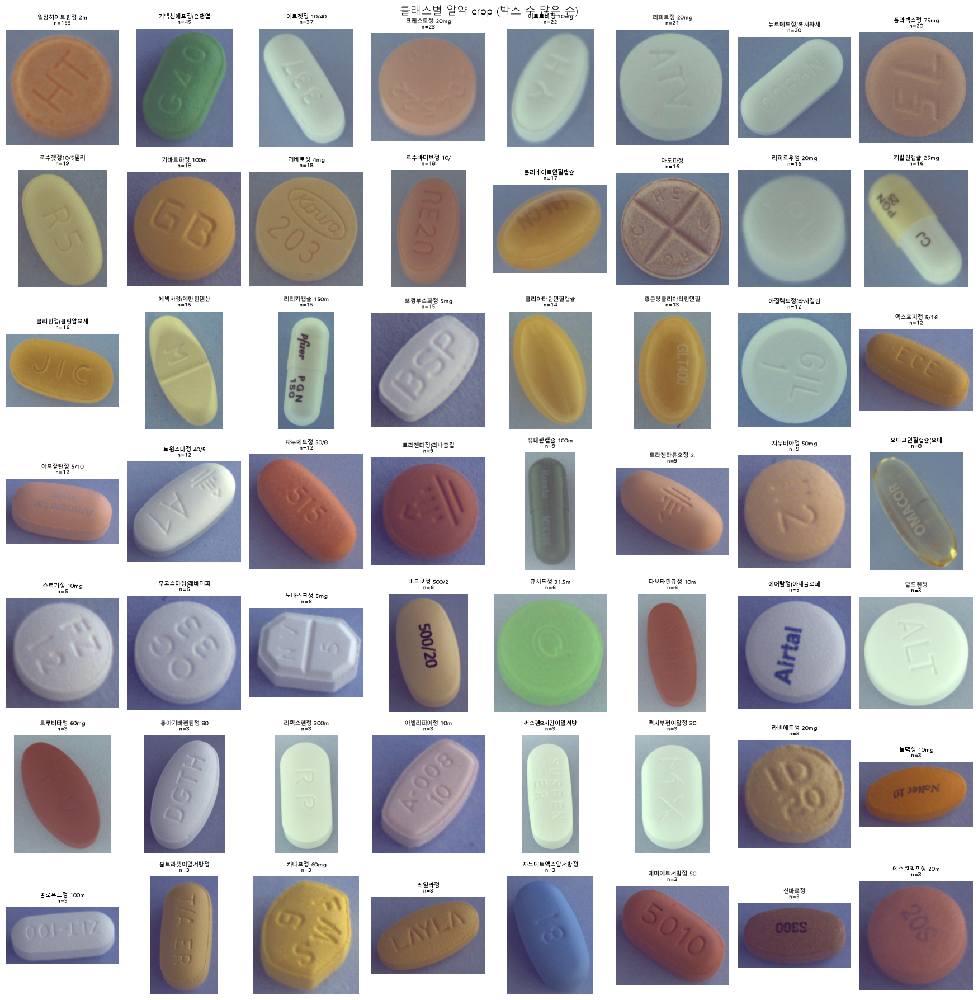

In [20]:
first = box.sort_values("file_name").drop_duplicates("category_id").set_index("category_id").loc[cls["category_id"]]
ncols = 8
nrows = int(np.ceil(len(first) / ncols))
fig, axes = plt.subplots(nrows, ncols, figsize=(2.2 * ncols, 2.6 * nrows))
for ax in axes.flat:
    ax.axis("off")
for ax, (cid, r) in zip(axes.flat, first.iterrows()):
    crop = Image.open(TRAIN_IMG_DIR / r.file_name).crop((r.x, r.y, r.x2, r.y2))
    ax.imshow(crop)
    ax.set_title(f"{str(r[NAME_COL])[:10]}\nn={cls.set_index('category_id').loc[cid, 'n_boxes']}", fontsize=7)
fig.suptitle("클래스별 알약 crop (박스 수 많은 순)", fontsize=14)
plt.tight_layout()
save_fig(fig, "09_class_crops")
plt.show()

## 7. 데이터 누수 위험과 검증 분할 전략
같은 알약 조합이 **카메라 각도만 바꿔 여러 장** 찍혀 있다면, 같은 조합이 train과 val에 나뉘어 들어갈 때
사실상 같은 장면을 맞히는 셈이 된다. 그러면 val 점수가 부풀려진다(**누수**).

조합 수: 114 / 조합당 이미지 수: {3: 40, 2: 38, 1: 36}
같은 조합 이미지 사이의 차이: 카메라 각도 [np.int64(70), np.int64(75), np.int64(90)]


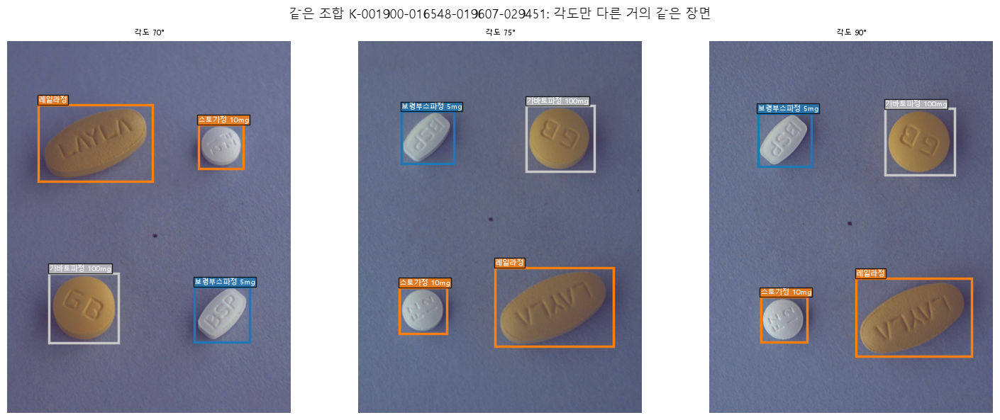

In [21]:
combo_counts = img_df.groupby("combo").size()
print(f"조합 수: {len(combo_counts)} / 조합당 이미지 수: {dict(Counter(combo_counts))}")
print("같은 조합 이미지 사이의 차이: 카메라 각도", sorted(img_df["camera_la"].unique()))

ex_combo = combo_counts[combo_counts == combo_counts.max()].index[0]
ex_files = img_df[img_df["combo"] == ex_combo]["file_name"].tolist()[:3]
fig, axes = plt.subplots(1, len(ex_files), figsize=(5 * len(ex_files), 6))
for ax, f in zip(np.atleast_1d(axes), ex_files):
    draw_boxes(ax, f, title=f"각도 {f.split('_')[5]}°")
fig.suptitle(f"같은 조합 {ex_combo}: 각도만 다른 거의 같은 장면", fontsize=13)
plt.tight_layout()
save_fig(fig, "10_same_combo_angles")
plt.show()

In [22]:
# 클래스 동시 출현: 함께 자주 놓이는 약 → 조합 단위로 나눌 때 클래스 쏠림 확인용
pair_counts = Counter()
for codes in img_df.drop_duplicates("combo")["expected_codes"]:
    pair_counts.update(combinations(codes, 2))
name_of = cls.set_index("category_id")["name"].to_dict()
print("자주 함께 나오는 약 쌍 Top 5 (조합 기준):")
for (a, b), c in pair_counts.most_common(5):
    print(f"  {name_of.get(a, a)} + {name_of.get(b, b)}: {c}개 조합")

자주 함께 나오는 약 쌍 Top 5 (조합 기준):
  일양하이트린정 2mg + 뉴로메드정(옥시라세탐): 10개 조합
  일양하이트린정 2mg + 아토르바정 10mg: 10개 조합
  일양하이트린정 2mg + 아토젯정 10/40mg: 10개 조합
  일양하이트린정 2mg + 로수바미브정 10/20mg: 10개 조합
  일양하이트린정 2mg + 크레스토정 20mg: 9개 조합


In [23]:
# 조합 단위 분할 시 val에 들어갈 수 없는(= 1개 조합에만 있는) 클래스의 박스 비중
single = cls[cls["n_combos"] == 1]
print(f"1개 조합에만 있는 클래스 {len(single)}개 → 이 클래스들은 조합 단위 분할에서 train/val 중 한쪽에만 들어간다.")
single[["name", "n_boxes", "n_images", "n_combos"]]

1개 조합에만 있는 클래스 17개 → 이 클래스들은 조합 단위 분할에서 train/val 중 한쪽에만 들어간다.


,name,n_boxes,n_images,n_combos
39,알드린정,3,3,1
40,트루비타정 60mg/병,3,3,1
41,동아가바펜틴정 800mg,3,3,1
42,리렉스펜정 300mg/PTP,3,3,1
43,아빌리파이정 10mg,3,3,1
44,써스펜8시간이알서방정 650mg,3,3,1
45,맥시부펜이알정 300mg,3,3,1
46,라비에트정 20mg,3,3,1
47,놀텍정 10mg,3,3,1
48,졸로푸트정 100mg,3,3,1


## 8. Train vs Test 분포 비교
테스트 라벨은 없지만 **이미지 통계(밝기·색)** 는 비교할 수 있다. 분포가 다르면 색 증강이 필요하다.

                R                 G                 B        brightness       contrast     
             mean   std        mean   std        mean   std        mean   std     mean  std
split                                                                                      
test   111.699997  16.6  121.300003  18.6  144.899994  11.0  125.900002  14.6     26.5  3.8
train  115.800003  13.1  129.800003  15.6  148.800003  10.0  131.500000  12.2     23.6  2.9


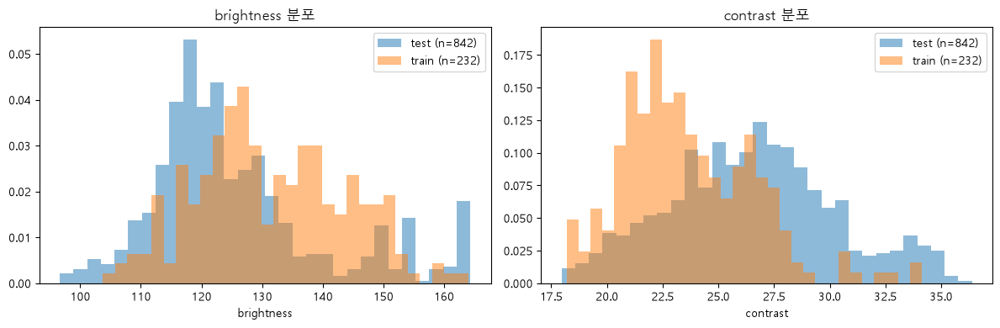

In [24]:
def image_stats(path: Path) -> dict:
    im = Image.open(path).convert("RGB")
    im.thumbnail((244, 320))
    a = np.asarray(im, dtype=np.float32)
    return {"R": a[..., 0].mean(), "G": a[..., 1].mean(), "B": a[..., 2].mean(), "brightness": a.mean(), "contrast": a.std()}


train_stats = pd.DataFrame([image_stats(TRAIN_IMG_DIR / f) for f in train_files]).assign(split="train")
test_stats = pd.DataFrame([image_stats(p) for p in test_files]).assign(split="test")
stats = pd.concat([train_stats, test_stats], ignore_index=True)
print(stats.groupby("split")[["R", "G", "B", "brightness", "contrast"]].agg(["mean", "std"]).round(1))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, col in zip(axes, ["brightness", "contrast"]):
    for split, g in stats.groupby("split"):
        ax.hist(g[col], bins=30, alpha=0.5, density=True, label=f"{split} (n={len(g)})")
    ax.set(title=f"{col} 분포", xlabel=col)
    ax.legend()
plt.tight_layout()
save_fig(fig, "11_train_vs_test_stats")
plt.show()

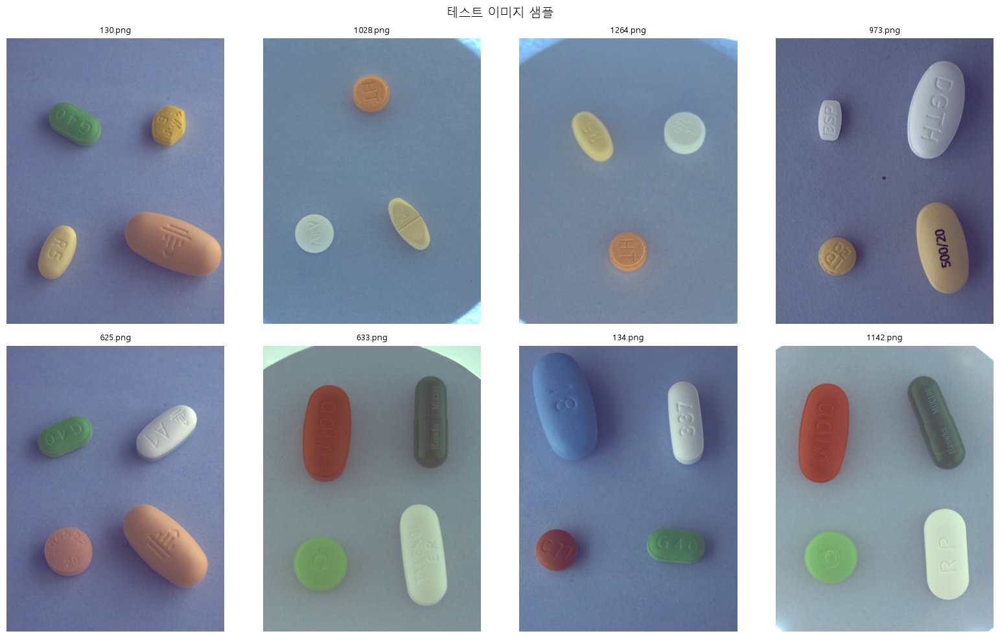

In [25]:
rng = np.random.default_rng(42)
show = rng.choice(len(test_files), 8, replace=False)
fig, axes = plt.subplots(2, 4, figsize=(16, 10))
for ax, i in zip(axes.flat, show):
    ax.imshow(Image.open(test_files[i]))
    ax.set_title(test_files[i].name, fontsize=9)
    ax.axis("off")
fig.suptitle("테스트 이미지 샘플", fontsize=14)
plt.tight_layout()
save_fig(fig, "12_test_samples")
plt.show()

### 학습 이미지 샘플 (정답 박스)

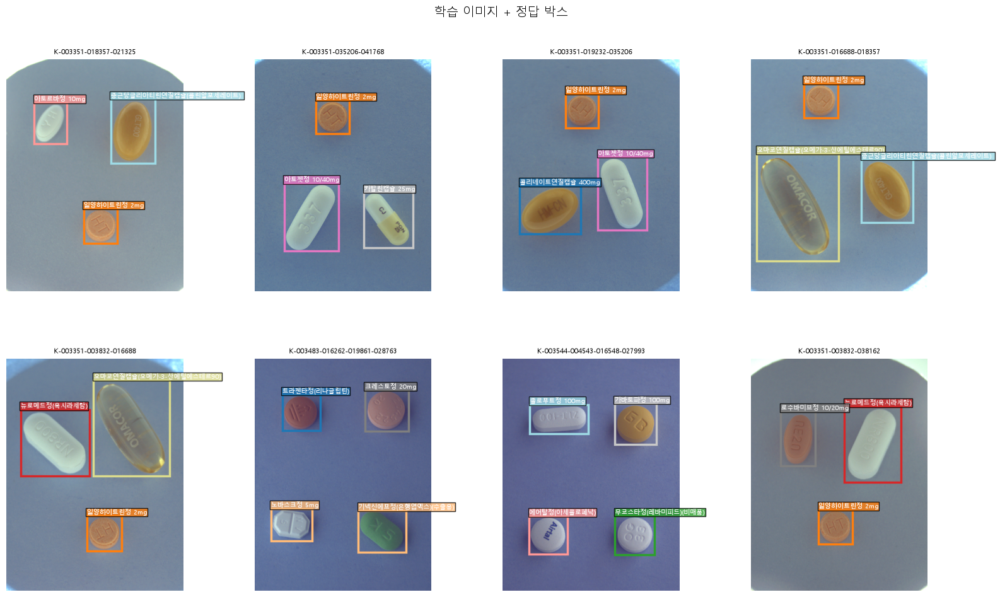

In [26]:
show = rng.choice(train_files, 8, replace=False)
fig, axes = plt.subplots(2, 4, figsize=(16, 10))
for ax, f in zip(axes.flat, show):
    draw_boxes(ax, f, title=f.split("_")[0])
fig.suptitle("학습 이미지 + 정답 박스", fontsize=14)
plt.tight_layout()
save_fig(fig, "13_train_samples")
plt.show()

## 9. 산출물 저장
- `class_map.csv`: 원래 `category_id`(약 코드) ↔ YOLO 클래스 번호(0~55). **제출 파일에서 원래 코드로 되돌릴 때 필요하다.**
- `image_meta.csv`: 이미지별 조합, 각도, 누락 정보. **조합 단위 검증 분할**에 쓴다.

In [27]:
class_map = (
    ann.groupby("category_id")
    .agg(dl_name=("dl_name", "first"), dl_name_en=("dl_name_en", "first"), n_boxes=("file_name", "size"),
         n_images=("file_name", "nunique"), n_combos=("combo", "nunique"))
    .reset_index()
    .sort_values("category_id")
)
class_map.insert(0, "yolo_id", range(len(class_map)))
class_map.to_csv(OUT_DIR / "class_map.csv", index=False, encoding="utf-8-sig")

img_df.assign(
    has_missing=img_df["missing_codes"].str.len() > 0,
    has_invalid_box=img_df["file_name"].isin(bad["file_name"]),
).to_csv(OUT_DIR / "image_meta.csv", index=False, encoding="utf-8-sig")

print("저장 완료:", OUT_DIR / "class_map.csv", OUT_DIR / "image_meta.csv")
print("그래프:", sorted(p.name for p in FIG_DIR.glob("*.png")))

저장 완료: C:\Users\user\Desktop\ai_15기\###프로젝트\pill-detection\reports\class_map.csv C:\Users\user\Desktop\ai_15기\###프로젝트\pill-detection\reports\image_meta.csv
그래프: ['01_label_problems.png', '01b_invalid_box_candidates.png', '02_class_distribution.png', '03_class_longtail.png', '04_pills_per_image.png', '05_bbox_stats.png', '06_size_vs_physical.png', '07_size_by_angle.png', '08_capture_conditions.png', '09_class_crops.png', '10_same_combo_angles.png', '11_train_vs_test_stats.png', '12_test_samples.png', '13_train_samples.png', '14_segmentation_steps.png', '15_label_audit_hist.png', '16_label_fixes_before_after.png', '17_fold_distribution.png', '18_yolo_export_check.png']


## 10. 결론: EDA → 모델링 의사결정

| 발견 | 근거 | 결정 |
|---|---|---|
| **데이터가 매우 적다** | 학습 232장 vs 테스트 842장 | COCO 사전학습 YOLO를 **파인튜닝**한다. 처음부터 학습하지 않는다 |
| **심한 클래스 불균형** | 최대 153 vs 최소 3 (약 50배), 박스 10개 미만 클래스가 다수 | 희귀 클래스 오버샘플링 / copy-paste 증강, 클래스별 AP를 따로 확인 |
| **극소수 클래스** | 17개 클래스는 **같은 장면을 각도만 바꾼 3장**이 전부 | 사실상 1장짜리 클래스. **Copy-Paste 증강**(알약 crop을 다른 배경에 붙이기)으로 다양한 맥락을 만든다 |
| **라벨 누락** | 8장 모두 빠진 알약이 사진에 **실제로 있음** | 그대로 쓰면 오답 학습. 박스를 **직접 보완**(8개뿐)하거나, 1차 모델로 의사 라벨을 만든 뒤 눈으로 검수 |
| **잘못된 박스** | x=6567 (이미지 폭 976 초과), 박스 없는 알약이 사진에 있음 | 후보 좌표를 그려 확인한 결과 **x=567**이 정답 → 수정해서 사용 |
| **같은 조합 × 3각도** | 조합당 이미지 1~3장, 각도만 다름 | 이미지 단위 무작위 분할은 **누수**. **조합(combo) 단위 GroupKFold**로 검증 |
| **고정된 배치 위치** | 박스 중심이 몇 개 슬롯에 집중 | 위치 편향 방지를 위해 이동·모자이크 증강 |
| **촬영 조건이 균일** | 메타상 배경·조명·거리 고정, 각도만 70/75/90° | 기하 증강(회전, 뒤집기, 스케일)이 핵심 |
| **Test가 조금 더 어둡고 대비가 큼** | 밝기 평균 125.9 vs 131.5, 대비 26.5 vs 23.6, 배경 색조도 이미지마다 다름 | 밝기·대비·색조(HSV) 증강을 적당히 넣어 분포 차이를 메운다 |
| **박스가 크다** | 짧은 변 125px 이상, 면적 비율 수 % | 작은 물체 문제는 없음. 640~1024 해상도로도 충분, 각인 식별을 위해 큰 해상도도 실험 |
| **생김새가 비슷한 클래스** | 같은 모양·색 그룹 다수 | 각인 같은 세부 특징이 중요 → 높은 입력 해상도, 큰 모델 비교 |
| **알약 회전 방향이 자유롭다** | 원형·타원형, 위에서 촬영 | 상하·좌우 뒤집기, 90° 회전 증강이 라벨을 해치지 않음 |

**다음 단계 (02_preprocess)**: 라벨 병합·정제 → COCO→YOLO 변환 → 조합 단위 분할 → 데이터셋 yaml 생성